# Analyse I: Vorverarbeitetes Korpus

Überblick über Dokumente, Sätze, Tokens und Lemmafrequenzen je Jahr.

In [21]:
import polars as pl

from zeitenwende_sgns.config import PREPROCESSED_DIR

pl.Config.set_tbl_rows(30)

SOURCE = "cpp_bt"

docs = pl.scan_parquet(PREPROCESSED_DIR / SOURCE / "*.parquet").with_columns(
    pl.col("date").dt.year().alias("year")
)

## Dokumente, Sätze und Tokens je Jahr

In [22]:
overview = (
    docs.group_by("year")
    .agg(
        pl.len().alias("docs"),
        pl.col("text_preprocessed").list.len().sum().alias("sentences"),
        pl.col("text_preprocessed")
        .list.eval(pl.element().list.len())
        .list.sum()
        .sum()
        .alias("tokens"),
    )
    .sort("year")
    .collect(engine="streaming")
)
overview

year,docs,sentences,tokens
i32,u32,u32,u32
2014,4543,260765,4410921
2015,5339,263728,4515434
2016,5110,237894,4058752
2017,3716,162583,2773097
2018,6356,265882,4378807
2019,7494,284224,4691181
2020,7488,271997,4547762
2021,5549,194372,3273833
2022,8185,296845,4931765


In [23]:
overview.sum().with_columns(year=None)

year,docs,sentences,tokens
null,u32,u32,u32
null,77517,3025932,50378124


## Lemmafrequenzen

Eine Tabelle mit Häufigkeiten je Jahr, Lemma und POS-Tag, aus der alles Weitere abgeleitet wird.

In [24]:
counts = (
    docs.select("year", pl.col("text_preprocessed").alias("token"))
    .explode("token")
    .explode("token")
    .select(
        "year",
        pl.col("token").struct.field("lemma"),
        pl.col("token").struct.field("upos"),
    )
    .group_by("year", "lemma", "upos")
    .len("count")
    .collect(engine="streaming")
)

words = counts.filter(pl.col("upos") != "PUNCT")

In [25]:
pl.DataFrame(
    {
        "tokens": [counts["count"].sum()],
        "tokens_no_punct": [words["count"].sum()],
        "lemmas": [words["lemma"].n_unique()],
        "lemmas_freq_ge_5": [
            words.group_by("lemma")
            .agg(pl.col("count").sum())
            .filter(pl.col("count") >= 5)
            .height
        ],
    }
)

tokens,tokens_no_punct,lemmas,lemmas_freq_ge_5
i64,i64,i64,i64
50378124,43529693,356220,87512


### Insgesamt

In [26]:
lemma_totals = (
    words.group_by("lemma").agg(pl.col("count").sum()).sort("count", descending=True)
)
lemma_totals.head(30)

lemma,count
str,u32
"""der""",4366408
"""und""",1287232
"""sein""",1137745
"""wir""",941165
"""ein""",893670
"""in""",766063
"""haben""",606371
"""sie""",587048
"""werden""",530552


In [27]:
# Häufigste Inhaltswörter
(
    words.filter(pl.col("upos").is_in(["NOUN", "PROPN", "VERB", "ADJ"]))
    .group_by("lemma", "upos")
    .agg(pl.col("count").sum())
    .sort("count", descending=True)
    .head(30)
)

lemma,upos,count
str,str,u32
"""Herr""","""NOUN""",155924
"""sagen""","""VERB""",139039
"""haben""","""VERB""",126825
"""geben""","""VERB""",123846
"""Jahr""","""NOUN""",119224
"""machen""","""VERB""",107557
"""Kollege""","""NOUN""",106905
"""Mensch""","""NOUN""",103503
"""gehen""","""VERB""",103278


### Je Jahr

In [28]:
(
    words.group_by("year")
    .agg(
        pl.col("count").sum().alias("tokens"),
        pl.col("lemma").n_unique().alias("lemmas"),
    )
    .with_columns((pl.col("lemmas") / pl.col("tokens")).alias("type_token_ratio"))
    .sort("year")
)

year,tokens,lemmas,type_token_ratio
i32,u32,u32,f64
2014,3833803,79167,0.02065
2015,3922205,84162,0.021458
2016,3521785,82799,0.023511
2017,2408724,68375,0.028386
2018,3774815,83421,0.022099
2019,4048049,91169,0.022522
2020,3920110,86849,0.022155
2021,2827852,75946,0.026856
2022,4257423,86204,0.020248


In [29]:
lemma_by_year = (
    words.group_by("year", "lemma")
    .agg(pl.col("count").sum())
    .with_columns(
        (pl.col("count") / pl.col("count").sum().over("year") * 1e6).alias(
            "per_million"
        )
    )
)

# Top-20-Lemmata je Jahr
(
    lemma_by_year.sort("count", descending=True)
    .group_by("year", maintain_order=True)
    .head(20)
    .with_columns(pl.int_range(1, pl.len() + 1).over("year").alias("rank"))
    .pivot("year", index="rank", values="lemma", sort_columns=True)
)

rank,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
i64,str,str,str,str,str,str,str,str,str,str,str,str
1,"""der""","""der""","""der""","""der""","""der""","""der""","""der""","""der""","""der""","""der""","""der""","""der"""
2,"""und""","""und""","""und""","""und""","""und""","""und""","""und""","""und""","""und""","""und""","""und""","""und"""
3,"""sein""","""sein""","""sein""","""sein""","""sein""","""sein""","""sein""","""sein""","""sein""","""sein""","""sein""","""sein"""
4,"""wir""","""ein""","""wir""","""ein""","""wir""","""wir""","""wir""","""wir""","""wir""","""wir""","""wir""","""wir"""
5,"""ein""","""wir""","""ein""","""wir""","""ein""","""ein""","""ein""","""ein""","""ein""","""ein""","""ein""","""ein"""
6,"""in""","""in""","""in""","""in""","""in""","""in""","""in""","""in""","""in""","""in""","""in""","""in"""
7,"""haben""","""haben""","""haben""","""haben""","""sie""","""sie""","""haben""","""haben""","""sie""","""sie""","""sie""","""sie"""
8,"""werden""","""werden""","""werden""","""werden""","""haben""","""haben""","""sie""","""sie""","""haben""","""haben""","""haben""","""haben"""
9,"""ich""","""ich""","""ich""","""ich""","""werden""","""werden""","""es""","""werden""","""werden""","""es""","""es""","""werden"""


## Zielwörter je Jahr

In [30]:
TARGETS = ["Zeitenwende", "Krieg", "Frieden", "Sicherheit"]

target_freqs = lemma_by_year.filter(pl.col("lemma").is_in(TARGETS))

target_freqs.pivot("lemma", index="year", values="count", sort_columns=True).sort(
    "year"
)

year,Frieden,Krieg,Sicherheit,Zeitenwende
i32,u32,u32,u32,u32
2014,476,586,1158,10
2015,485,869,1410,4
2016,422,582,1386,5
2017,356,352,1200,6
2018,556,543,1532,4
2019,672,520,1577,2
2020,412,391,1340,8
2021,272,273,962,3
2022,691,2422,1929,578


In [31]:
target_freqs.pivot("lemma", index="year", values="per_million", sort_columns=True).sort(
    "year"
).with_columns(pl.exclude("year").round(1))

year,Frieden,Krieg,Sicherheit,Zeitenwende
i32,f64,f64,f64,f64
2014,124.2,152.9,302.0,2.6
2015,123.7,221.6,359.5,1.0
2016,119.8,165.3,393.6,1.4
2017,147.8,146.1,498.2,2.5
2018,147.3,143.8,405.8,1.1
2019,166.0,128.5,389.6,0.5
2020,105.1,99.7,341.8,2.0
2021,96.2,96.5,340.2,1.1
2022,162.3,568.9,453.1,135.8


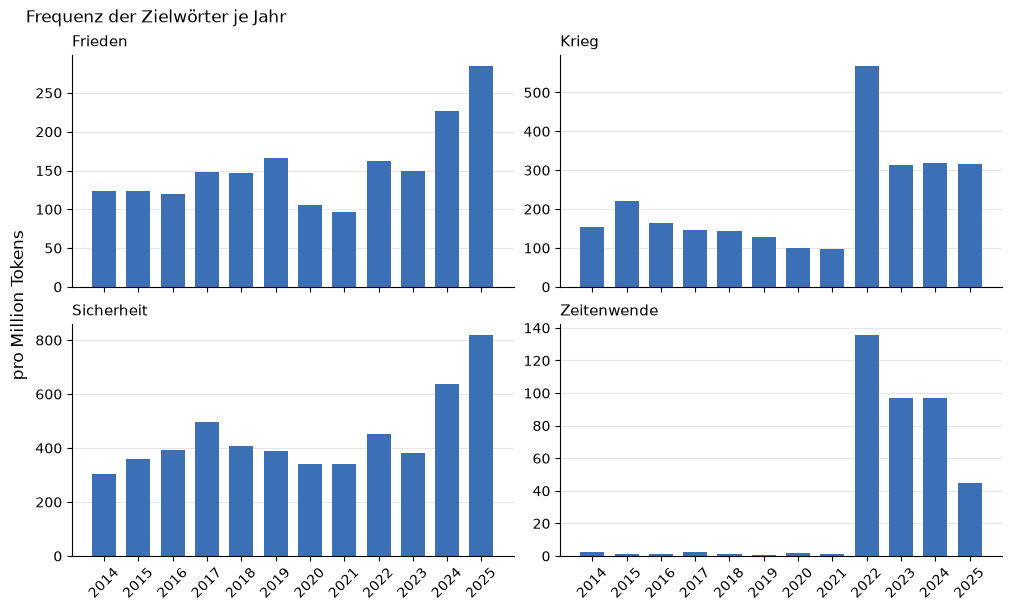

In [32]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True, layout="constrained")

for ax, target in zip(axes.flat, sorted(TARGETS)):
    data = target_freqs.filter(pl.col("lemma") == target).sort("year")
    ax.bar(data["year"], data["per_million"], width=0.7, color="#3b6fb6")
    ax.set_title(target, loc="left", fontsize=11)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="0.9")
    ax.set_axisbelow(True)
    ax.set_xticks(data["year"], data["year"], rotation=45)

fig.supylabel("pro Million Tokens")
fig.suptitle("Frequenz der Zielwörter je Jahr", x=0.02, ha="left")
plt.show()

## Zielwörter aus der Masterliste

Gezählt wird nach exakter Übereinstimmung mit dem Lemma. Nicht gefunden werden:

- Mehrwortausdrücke (z. B. *Kalter Krieg*)
- Einträge, die nicht in Lemmaform stehen (z. B. *Fakten* statt *Faktum*)
- Formen, die der Lemmatisierer nicht zurückführt (z. B. *Russlands*), sofern sie nicht in den Lemma-Overrides stehen (siehe unten)

In [33]:
from zeitenwende_sgns.targets import load_targets

masterlist = pl.DataFrame({"lemma": load_targets()})
masterlist.height

607

In [34]:
n_tokens = words["count"].sum()

masterlist_totals = (
    masterlist.join(lemma_totals, on="lemma", how="left")
    .with_columns(pl.col("count").fill_null(0))
    .with_columns((pl.col("count") / n_tokens * 1e6).round(2).alias("per_million"))
    .sort("count", descending=True)
)
masterlist_totals

lemma,count,per_million
str,u32,f64
"""Euro""",65205,1497.94
"""Milliarde""",33381,766.86
"""Europa""",32056,736.42
"""Sicherheit""",18951,435.36
"""Wirtschaft""",16688,383.37
"""Demokratie""",14839,340.89
"""Lage""",13580,311.97
"""Einsatz""",12632,290.19
"""Schutz""",12501,287.18


In [35]:
# Nicht im Korpus gefunden
masterlist_totals.filter(pl.col("count") == 0)["lemma"].to_list()

['Kalter Krieg',
 'Ukraine-Invasion',
 'Heldenhaftigkeit',
 'EU-Russland',
 'Hybridkrieg',
 'Kriegsberichterstattung',
 'Schlangeninsel',
 'Heldennarrativ']

In [36]:
masterlist_by_year = masterlist.join(lemma_by_year, on="lemma", how="inner")


def by_year(values: str) -> pl.DataFrame:
    return (
        masterlist_by_year.pivot(
            "year", index="lemma", values=values, sort_columns=True
        )
        .fill_null(0)
        .join(masterlist_totals.select("lemma", total="count"), on="lemma")
        .sort("total", descending=True)
    )


by_year("count")

lemma,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,total
str,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
"""Euro""",7060,5543,5058,2392,6677,5358,5579,2880,7871,5188,5218,6381,65205
"""Milliarde""",3443,2653,2313,996,3291,2545,3162,1456,3966,2673,2834,4049,33381
"""Europa""",3441,3696,2406,2035,3590,3079,2797,1464,2733,2382,2424,2009,32056
"""Sicherheit""",1158,1410,1386,1200,1532,1577,1340,962,1929,1650,2387,2420,18951
"""Wirtschaft""",1584,1396,901,644,1082,1307,1637,957,1489,1921,2014,1756,16688
"""Demokratie""",639,574,790,550,1071,1353,1423,1159,1658,1616,2285,1721,14839
"""Lage""",1095,1182,924,694,1026,1029,1448,1261,1506,1243,1200,972,13580
"""Einsatz""",1361,1210,1023,885,1158,1136,1039,883,1203,1004,1002,728,12632
"""Schutz""",961,1102,1246,825,924,1031,1065,1025,1164,1040,1086,1032,12501


In [37]:
by_year("per_million").with_columns(pl.exclude("lemma", "total").round(1))

lemma,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,total
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,u32
"""Euro""",1841.5,1413.2,1436.2,993.1,1768.8,1323.6,1423.2,1018.4,1848.8,1203.7,1390.5,2161.4,65205
"""Milliarde""",898.1,676.4,656.8,413.5,871.8,628.7,806.6,514.9,931.5,620.2,755.2,1371.5,33381
"""Europa""",897.5,942.3,683.2,844.8,951.0,760.6,713.5,517.7,641.9,552.7,645.9,680.5,32056
"""Sicherheit""",302.0,359.5,393.6,498.2,405.8,389.6,341.8,340.2,453.1,382.8,636.1,819.7,18951
"""Wirtschaft""",413.2,355.9,255.8,267.4,286.6,322.9,417.6,338.4,349.7,445.7,536.7,594.8,16688
"""Demokratie""",166.7,146.3,224.3,228.3,283.7,334.2,363.0,409.9,389.4,375.0,608.9,582.9,14839
"""Lage""",285.6,301.4,262.4,288.1,271.8,254.2,369.4,445.9,353.7,288.4,319.8,329.2,13580
"""Einsatz""",355.0,308.5,290.5,367.4,306.8,280.6,265.0,312.3,282.6,233.0,267.0,246.6,12632
"""Schutz""",250.7,281.0,353.8,342.5,244.8,254.7,271.7,362.5,273.4,241.3,289.4,349.6,12501


## Kandidaten für Lemma-Overrides

Wortformen, die wie Flexionsformen eines Zielworts aussehen, aber ein anderes Lemma bekommen haben. Die Kandidaten prüfen und passende Zeilen in `resources/lemma_overrides.tsv` übernehmen; die Vorverarbeitung verwendet die Datei beim nächsten Lauf. Zeilen, in denen das Zielwort selbst nicht in Lemmaform steht (z. B. *Fakten*), besser in `resources/zielwoerter.txt` korrigieren.

In [38]:
from zeitenwende_sgns.config import RESOURCES_DIR
from zeitenwende_sgns.targets import override_candidates

candidates = override_candidates(
    PREPROCESSED_DIR / SOURCE, masterlist["lemma"].to_list()
)
candidates.write_csv(RESOURCES_DIR / "lemma_override_candidates.tsv", separator="\t")
candidates

form,lemma_predicted,lemma_corrected,count
str,str,str,u32
"""Lager""","""Lager""","""Lage""",455
"""Nations""","""Nations""","""Nation""",47
"""Geschehene""","""Geschehene""","""Geschehen""",38
"""Hybride""","""Hybrid""","""hybrid""",34
"""Russisch""","""Russisch""","""russisch""",31
"""Stärker""","""stark""","""Stärke""",24
"""Hybrid""","""Hybrid""","""hybrid""",19
"""Boten""","""Bote""","""Bot""",15
"""Bomber""","""Bomber""","""Bombe""",10
